In [6]:
import pandas as pd
import os

# Dataset location
file_path = "C:/Users/dhivakar/Desktop/Groundnut-Mandi-Price-Analysis-Forecasting/dataset/raw/2025.csv"

# Check whether the file exists
print("File exists:", os.path.exists(file_path))

# Read the first 5 rows
df = pd.read_csv(file_path, nrows=5)

# Display the data
df

File exists: True


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code
0,Andhra Pradesh,Chittor,Chittoor,Gur (Jaggery),NO 2,FAQ,2025-01-01,3200.0,3500.0,3500.0,74
1,Tamil Nadu,The Nilgiris,Gudalur (Uzhavar Sandhai ),Garlic,Average,Local,2025-01-01,28000.0,30000.0,30000.0,25
2,Tamil Nadu,The Nilgiris,Gudalur (Uzhavar Sandhai ),Ginger (Green),Green Ginger,Local,2025-01-01,7000.0,8000.0,8000.0,103
3,Tamil Nadu,The Nilgiris,Gudalur (Uzhavar Sandhai ),Green Chilli,Green Chilly,Local,2025-01-01,4500.0,5000.0,5000.0,87
4,Tamil Nadu,The Nilgiris,Gudalur (Uzhavar Sandhai ),Mint (Pudina),Mint (Pudina),Local,2025-01-01,4500.0,5000.0,5000.0,360


In [7]:
# Load the complete 2025 dataset
df = pd.read_csv(file_path)

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Understand the data types
print("\nDataset information:")
df.info()

Dataset shape: (5819482, 11)

Column names:
['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_Price', 'Max_Price', 'Modal_Price', 'Commodity_Code']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5819482 entries, 0 to 5819481
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   State           str    
 1   District        str    
 2   Market          str    
 3   Commodity       str    
 4   Variety         str    
 5   Grade           str    
 6   Arrival_Date    str    
 7   Min_Price       float64
 8   Max_Price       float64
 9   Modal_Price     float64
 10  Commodity_Code  int64  
dtypes: float64(3), int64(1), str(7)
memory usage: 862.0 MB


In [8]:
# Find all commodity names containing 'groundnut'
groundnut_data = df[
    df["Commodity"].str.contains("groundnut", case=False, na=False)
]

print("Groundnut records:", len(groundnut_data))

groundnut_data.head()

Groundnut records: 35188


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code
710,Tamil Nadu,Salem,Thathakapatti (Uzhavar Sandhai ),Groundnut,Big (With Shell),Local,2025-01-01,6000.0,7000.0,7000.0,10
1017,Tamil Nadu,Thirupur,Tiruppur (North) (Uzhavar Sandhai ),Groundnut,Big (With Shell),Local,2025-01-01,5000.0,6000.0,6000.0,10
1246,Tamil Nadu,Thiruvannamalai,Tamarainagar (Uzhavar Sandhai ),Groundnut,Big (With Shell),Local,2025-01-01,6000.0,7000.0,7000.0,10
1304,Tamil Nadu,Thiruvannamalai,Tiruvannamalai (Uzhavar Sandhai ),Groundnut,Big (With Shell),Local,2025-01-01,6000.0,7000.0,7000.0,10
1408,Tamil Nadu,Thiruvannamalai,Polur (Uzhavar Sandhai ),Groundnut,Big (With Shell),Local,2025-01-01,4200.0,5000.0,5000.0,10


In [9]:
# Filter Groundnut records from Andhra Pradesh
ap_groundnut = df[
    (df["State"].str.strip().str.lower() == "andhra pradesh") &
    (df["Commodity"].str.strip().str.lower() == "groundnut")
].copy()

# Display the number of records
print("Andhra Pradesh Groundnut records:", len(ap_groundnut))

# Display first 10 records
ap_groundnut.head(10)

Andhra Pradesh Groundnut records: 883


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code
100514,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-06,4619.0,6783.0,5690.0,10
121281,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-07,3636.0,6534.0,4709.0,10
142124,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-08,4300.0,6783.0,4900.0,10
142193,Andhra Pradesh,Cuddapah,Cuddapah,Groundnut,Local,FAQ,2025-01-08,3669.0,6356.0,4656.0,10
162866,Andhra Pradesh,Cuddapah,Cuddapah,Groundnut,Local,FAQ,2025-01-09,2219.0,5899.0,5059.0,10
162914,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-09,3006.0,6788.0,4100.0,10
184067,Andhra Pradesh,Cuddapah,Cuddapah,Groundnut,Local,FAQ,2025-01-10,2879.0,5519.0,3919.0,10
184188,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-10,5342.0,6783.0,5607.0,10
203290,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-11,3339.0,6783.0,5242.0,10
289820,Andhra Pradesh,Cuddapah,Cuddapah,Groundnut,Local,FAQ,2025-01-16,4589.0,6089.0,4729.0,10


In [10]:
market_counts = (
    ap_groundnut["Market"]
    .value_counts()
    .reset_index()
)

market_counts.columns = ["Market", "Record_Count"]

market_counts.head(15)

,Market,Record_Count
0,Kurnool,202
1,Yemmiganur,195
2,Cuddapah,193
3,Adoni,189
4,Gudur,41
5,Lakkireddipally,20
6,Adoni APMC,9
7,Kurnool APMC,7
8,Yemmiganur APMC,7
9,Rapur,6


In [11]:
# Filter Kurnool market
kurnool = ap_groundnut[
    ap_groundnut["Market"].str.strip().str.lower() == "kurnool"
].copy()

# Convert Arrival_Date into date format
kurnool["Arrival_Date"] = pd.to_datetime(kurnool["Arrival_Date"])

# Sort records by date
kurnool = kurnool.sort_values("Arrival_Date")

print("Total Kurnool records:", len(kurnool))
print("First date:", kurnool["Arrival_Date"].min())
print("Last date:", kurnool["Arrival_Date"].max())
print("Unique trading dates:", kurnool["Arrival_Date"].nunique())

kurnool.head(10)

Total Kurnool records: 202
First date: 2025-01-06 00:00:00
Last date: 2025-11-05 00:00:00
Unique trading dates: 202


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code
100514,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-06,4619.0,6783.0,5690.0,10
121281,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-07,3636.0,6534.0,4709.0,10
142124,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-08,4300.0,6783.0,4900.0,10
162914,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-09,3006.0,6788.0,4100.0,10
184188,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-10,5342.0,6783.0,5607.0,10
203290,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-11,3339.0,6783.0,5242.0,10
289886,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,FAQ,2025-01-16,4112.0,6783.0,5355.0,10
312624,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,Non-FAQ,2025-01-17,2069.0,6609.0,6431.0,10
331452,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,Non-FAQ,2025-01-18,3116.0,6216.0,4940.0,10
364860,Andhra Pradesh,Kurnool,Kurnool,Groundnut,Local,Non-FAQ,2025-01-20,3222.0,6783.0,5319.0,10


In [12]:
print("Kurnool Groundnut Price Summary")

print(kurnool[["Min_Price", "Max_Price", "Modal_Price"]].describe())

Kurnool Groundnut Price Summary
         Min_Price    Max_Price  Modal_Price
count   202.000000   202.000000   202.000000
mean   3579.811881  6632.153465  5557.143564
std    1009.751959   472.391093   704.484218
min    1000.000000  4799.000000  3539.000000
25%    3016.500000  6390.750000  5139.000000
50%    3698.000000  6719.000000  5550.000000
75%    4198.750000  6940.750000  6000.750000
max    5656.000000  8000.000000  7440.000000


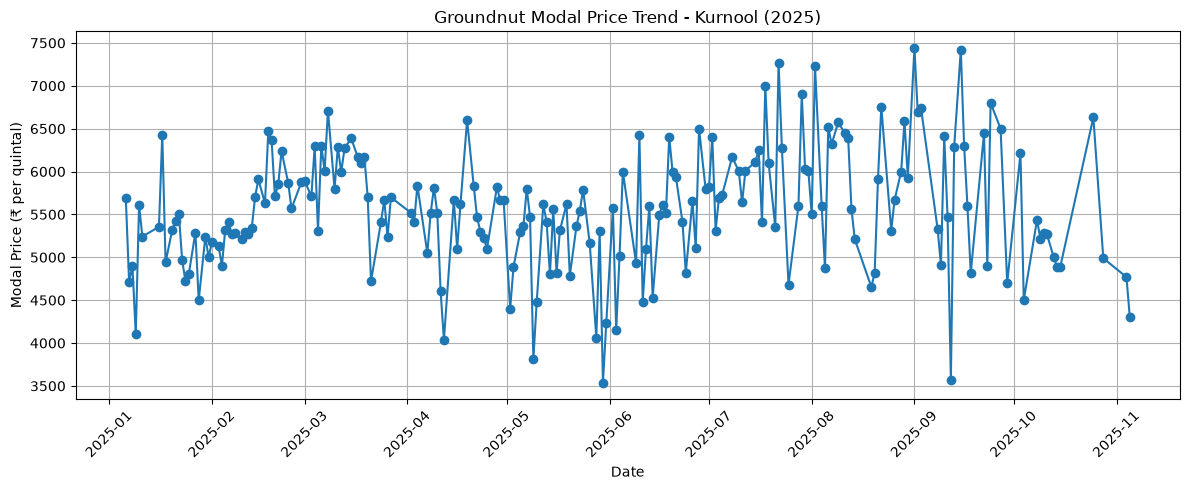

In [13]:
import matplotlib.pyplot as plt

# Calculate average modal price for each trading date
daily_prices = (
    kurnool.groupby("Arrival_Date")["Modal_Price"]
    .mean()
    .reset_index()
)

# Create the chart
plt.figure(figsize=(12, 5))

plt.plot(
    daily_prices["Arrival_Date"],
    daily_prices["Modal_Price"],
    marker="o",
    linewidth=1.5
)

plt.title("Groundnut Modal Price Trend - Kurnool (2025)")
plt.xlabel("Date")
plt.ylabel("Modal Price (₹ per quintal)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

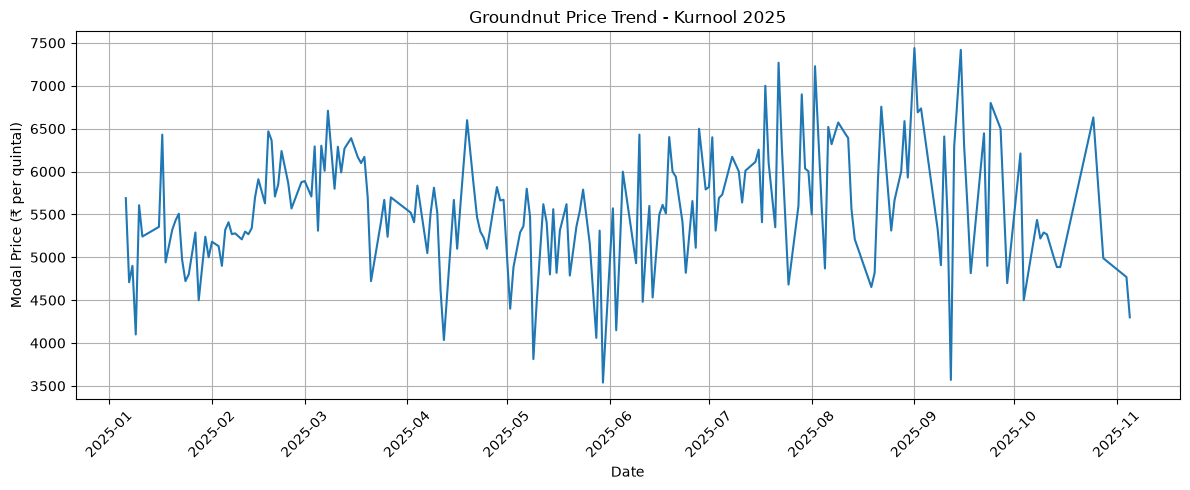

In [14]:
import os

os.makedirs("../visualizations", exist_ok=True)

plt.figure(figsize=(12, 5))
plt.plot(daily_prices["Arrival_Date"], daily_prices["Modal_Price"])

plt.title("Groundnut Price Trend - Kurnool 2025")
plt.xlabel("Date")
plt.ylabel("Modal Price (₹ per quintal)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig("../visualizations/kurnool_price_trend.png", dpi=300)
plt.show()

monthly analysis


In [15]:
# Create a copy of daily price data
monthly_data = daily_prices.copy()

# Extract month from Arrival_Date
monthly_data["Month"] = monthly_data["Arrival_Date"].dt.month

# Calculate average price for each month
monthly_prices = (
    monthly_data.groupby("Month")["Modal_Price"]
    .mean()
    .reset_index()
)

# Display results
print(monthly_prices)

    Month  Modal_Price
0       1  5144.789474
1       2  5581.363636
2       3  5896.761905
3       4  5446.333333
4       5  5017.541667
5       6  5456.818182
6       7  5989.136364
7       8  5892.800000
8       9  5906.722222
9      10  5301.727273
10     11  4534.500000


In [16]:
highest_month = monthly_prices.loc[
    monthly_prices["Modal_Price"].idxmax()
]

lowest_month = monthly_prices.loc[
    monthly_prices["Modal_Price"].idxmin()
]

print("Highest average price month:", highest_month["Month"])
print("Highest average modal price:", highest_month["Modal_Price"])

print("\nLowest average price month:", lowest_month["Month"])
print("Lowest average modal price:", lowest_month["Modal_Price"])

Highest average price month: 7.0
Highest average modal price: 5989.136363636364

Lowest average price month: 11.0
Lowest average modal price: 4534.5


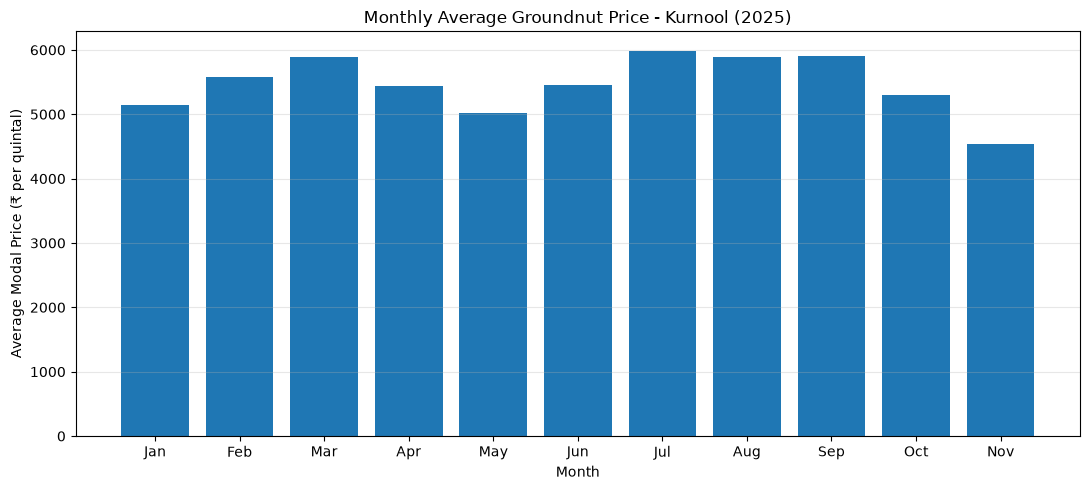

In [17]:
import matplotlib.pyplot as plt

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(11, 5))

plt.bar(
    [month_names[int(m)-1] for m in monthly_prices["Month"]],
    monthly_prices["Modal_Price"]
)

plt.title("Monthly Average Groundnut Price - Kurnool (2025)")
plt.xlabel("Month")
plt.ylabel("Average Modal Price (₹ per quintal)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Calculate monthly price volatility
monthly_volatility = (
    daily_prices.groupby(daily_prices["Arrival_Date"].dt.month)["Modal_Price"]
    .std()
    .reset_index()
)

monthly_volatility.columns = ["Month", "Price_Std_Dev"]

print(monthly_volatility)

    Month  Price_Std_Dev
0       1     507.734683
1       2     419.889843
2       3     463.413844
3       4     512.657228
4       5     638.193441
5       6     640.476284
6       7     587.321709
7       8     709.199742
8       9    1048.102308
9      10     615.932803
10     11     331.633080


In [19]:
most_volatile = monthly_volatility.loc[
    monthly_volatility["Price_Std_Dev"].idxmax()
]

least_volatile = monthly_volatility.loc[
    monthly_volatility["Price_Std_Dev"].idxmin()
]

print("Most volatile month:", int(most_volatile["Month"]))
print("Standard deviation:", round(most_volatile["Price_Std_Dev"], 2))

print("\nMost stable month:", int(least_volatile["Month"]))
print("Standard deviation:", round(least_volatile["Price_Std_Dev"], 2))

Most volatile month: 9
Standard deviation: 1048.1

Most stable month: 11
Standard deviation: 331.63


In [20]:
# Select the three markets
selected_markets = ["Kurnool", "Yemmiganur", "Cuddapah"]

market_data = ap_groundnut[
    ap_groundnut["Market"].isin(selected_markets)
].copy()

# Convert date
market_data["Arrival_Date"] = pd.to_datetime(
    market_data["Arrival_Date"]
)

# Calculate average modal price for each market
market_comparison = (
    market_data.groupby("Market")["Modal_Price"]
    .agg(["count", "mean", "min", "max", "std"])
    .round(2)
)

print(market_comparison)

            count     mean     min     max     std
Market                                            
Cuddapah      193  5175.32  3619.0  6569.0  691.77
Kurnool       202  5557.14  3539.0  7440.0  704.48
Yemmiganur    195  5378.55  3480.0  6950.0  755.58


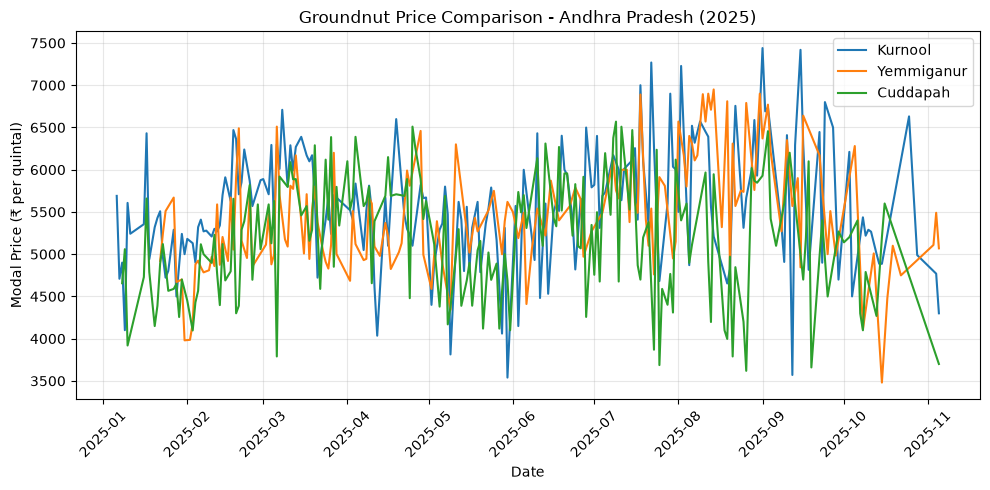

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for market in selected_markets:
    temp = market_data[market_data["Market"] == market]

    daily = (
        temp.groupby("Arrival_Date")["Modal_Price"]
        .mean()
        .sort_index()
    )

    plt.plot(daily.index, daily.values, label=market)

plt.title("Groundnut Price Comparison - Andhra Pradesh (2025)")
plt.xlabel("Date")
plt.ylabel("Modal Price (₹ per quintal)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
print(market_comparison)

            count     mean     min     max     std
Market                                            
Cuddapah      193  5175.32  3619.0  6569.0  691.77
Kurnool       202  5557.14  3539.0  7440.0  704.48
Yemmiganur    195  5378.55  3480.0  6950.0  755.58


## Key Findings

1. Kurnool recorded the highest average groundnut modal price
   among the three selected markets in 2025, at ₹5,557.14
   per quintal.

2. Cuddapah recorded the lowest average modal price,
   at ₹5,175.32 per quintal.

3. Yemmiganur showed the highest price variation, with a
   standard deviation of ₹755.58.

4. Groundnut modal prices fluctuated across all three markets
   during the study period.

5. These findings describe price differences and variation.
   They do not establish the causes of price movements.

In [23]:
print("First date:", kurnool["Arrival_Date"].min())
print("Last date:", kurnool["Arrival_Date"].max())

print("Total records:", len(kurnool))
print("Unique trading dates:", kurnool["Arrival_Date"].nunique())

print("Missing values:")
print(kurnool[["Arrival_Date", "Modal_Price"]].isnull().sum())

First date: 2025-01-06 00:00:00
Last date: 2025-11-05 00:00:00
Total records: 202
Unique trading dates: 202
Missing values:
Arrival_Date    0
Modal_Price     0
dtype: int64


model training

In [24]:
# Sort data chronologically
forecast_data = daily_prices.sort_values("Arrival_Date").copy()

# Calculate the split point
split_index = int(len(forecast_data) * 0.8)

# Split into training and testing data
train = forecast_data.iloc[:split_index].copy()
test = forecast_data.iloc[split_index:].copy()

print("Training records:", len(train))
print("Testing records:", len(test))

print("Training period:")
print(train["Arrival_Date"].min(), "to", train["Arrival_Date"].max())

print("Testing period:")
print(test["Arrival_Date"].min(), "to", test["Arrival_Date"].max())

Training records: 161
Testing records: 41
Training period:
2025-01-06 00:00:00 to 2025-08-13 00:00:00
Testing period:
2025-08-14 00:00:00 to 2025-11-05 00:00:00


In [25]:
# Get the last known training price
last_train_price = train["Modal_Price"].iloc[-1]

# Predict that same price for every test date
test = test.copy()
test["Baseline_Prediction"] = last_train_price

print("Last training price:", last_train_price)
print("\nActual vs predicted prices:")
print(test[["Arrival_Date", "Modal_Price", "Baseline_Prediction"]].head(10))

Last training price: 5562.0

Actual vs predicted prices:
    Arrival_Date  Modal_Price  Baseline_Prediction
161   2025-08-14       5210.0               5562.0
162   2025-08-19       4653.0               5562.0
163   2025-08-20       4820.0               5562.0
164   2025-08-21       5909.0               5562.0
165   2025-08-22       6756.0               5562.0
166   2025-08-25       5312.0               5562.0
167   2025-08-26       5667.0               5562.0
168   2025-08-28       6000.0               5562.0
169   2025-08-29       6588.0               5562.0
170   2025-08-30       5930.0               5562.0


In [26]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(
    test["Modal_Price"],
    test["Baseline_Prediction"]
)

rmse = np.sqrt(mean_squared_error(
    test["Modal_Price"],
    test["Baseline_Prediction"]
))

print("Baseline MAE:", round(mae, 2))
print("Baseline RMSE:", round(rmse, 2))

Baseline MAE: 750.63
Baseline RMSE: 884.48


In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create a copy of the data
train_ml = train.copy()
test_ml = test.copy()

# Convert dates into numeric values (days since first date)
start_date = forecast_data["Arrival_Date"].min()

train_ml["Days"] = (
    train_ml["Arrival_Date"] - start_date
).dt.days

test_ml["Days"] = (
    test_ml["Arrival_Date"] - start_date
).dt.days

# Select input and target
X_train = train_ml[["Days"]]
y_train = train_ml["Modal_Price"]

X_test = test_ml[["Days"]]
y_test = test_ml["Modal_Price"]

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict test prices
test_ml["Linear_Regression_Prediction"] = model.predict(X_test)

# Evaluate the model
lr_mae = mean_absolute_error(
    y_test,
    test_ml["Linear_Regression_Prediction"]
)

lr_rmse = np.sqrt(mean_squared_error(
    y_test,
    test_ml["Linear_Regression_Prediction"]
))

print("Linear Regression MAE:", round(lr_mae, 2))
print("Linear Regression RMSE:", round(lr_rmse, 2))

Linear Regression MAE: 809.12
Linear Regression RMSE: 929.58


In [28]:
# Predict each test price using the previous observed price
test["Previous_Price_Prediction"] = (
    forecast_data["Modal_Price"].shift(1).loc[test.index]
)

# Evaluate this baseline
previous_mae = mean_absolute_error(
    test["Modal_Price"],
    test["Previous_Price_Prediction"]
)

previous_rmse = np.sqrt(mean_squared_error(
    test["Modal_Price"],
    test["Previous_Price_Prediction"]
))

print("Previous Price MAE:", round(previous_mae, 2))
print("Previous Price RMSE:", round(previous_rmse, 2))

Previous Price MAE: 912.73
Previous Price RMSE: 1131.38


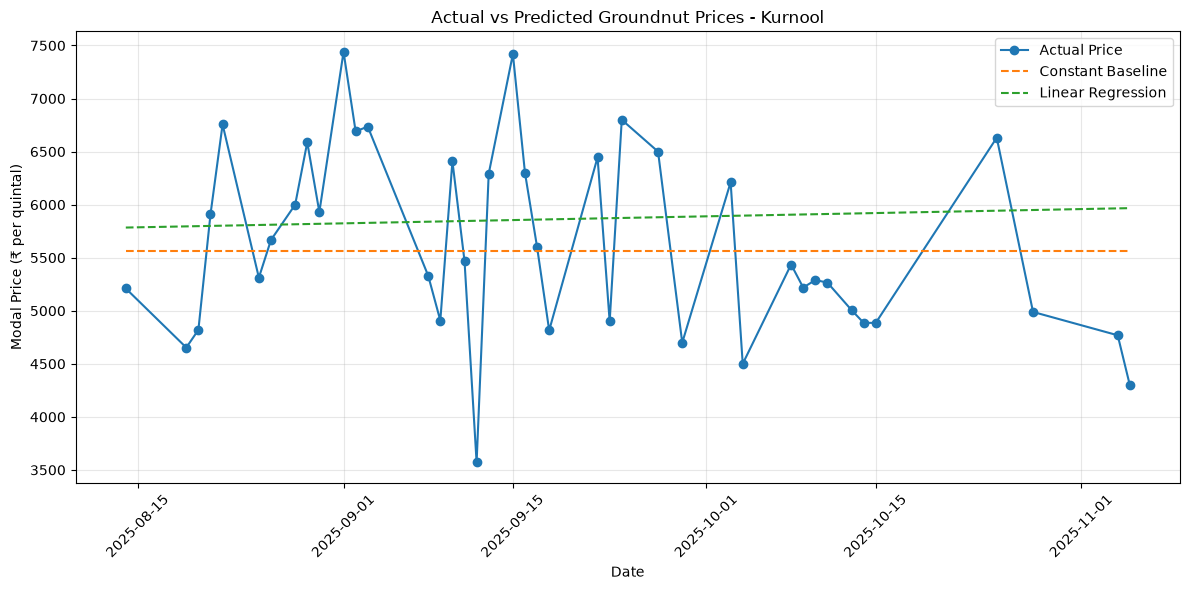

In [29]:
plt.figure(figsize=(12, 6))

plt.plot(
    test["Arrival_Date"],
    test["Modal_Price"],
    label="Actual Price",
    marker="o"
)

plt.plot(
    test["Arrival_Date"],
    test["Baseline_Prediction"],
    label="Constant Baseline",
    linestyle="--"
)

plt.plot(
    test_ml["Arrival_Date"],
    test_ml["Linear_Regression_Prediction"],
    label="Linear Regression",
    linestyle="--"
)

plt.title("Actual vs Predicted Groundnut Prices - Kurnool")
plt.xlabel("Date")
plt.ylabel("Modal Price (₹ per quintal)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create calendar features
train_rf = train.copy()
test_rf = test.copy()

for data in [train_rf, test_rf]:
    data["Month"] = data["Arrival_Date"].dt.month
    data["Day"] = data["Arrival_Date"].dt.day
    data["DayOfWeek"] = data["Arrival_Date"].dt.dayofweek
    data["DayOfYear"] = data["Arrival_Date"].dt.dayofyear

features = ["Month", "Day", "DayOfWeek", "DayOfYear"]

X_train_rf = train_rf[features]
y_train_rf = train_rf["Modal_Price"]

X_test_rf = test_rf[features]
y_test_rf = test_rf["Modal_Price"]

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

rf_model.fit(X_train_rf, y_train_rf)

# Predict
test_rf["RF_Prediction"] = rf_model.predict(X_test_rf)

# Evaluate
rf_mae = mean_absolute_error(
    y_test_rf,
    test_rf["RF_Prediction"]
)

rf_rmse = np.sqrt(mean_squared_error(
    y_test_rf,
    test_rf["RF_Prediction"]
))

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))

Random Forest MAE: 854.47
Random Forest RMSE: 997.2


In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Prepare data in date order
lag_data = forecast_data.sort_values("Arrival_Date").reset_index(drop=True).copy()

# Create features using previous observations only
lag_data["Lag_1"] = lag_data["Modal_Price"].shift(1)
lag_data["Lag_2"] = lag_data["Modal_Price"].shift(2)

lag_data["Rolling_Mean_3"] = (
    lag_data["Modal_Price"].shift(1).rolling(3).mean()
)

# Keep the original chronological split
train_lag = lag_data.iloc[:split_index].dropna().copy()
test_lag = lag_data.iloc[split_index:].dropna().copy()

features = ["Lag_1", "Lag_2", "Rolling_Mean_3"]

X_train_lag = train_lag[features]
y_train_lag = train_lag["Modal_Price"]

X_test_lag = test_lag[features]
y_test_lag = test_lag["Modal_Price"]

# Train model
lag_model = LinearRegression()
lag_model.fit(X_train_lag, y_train_lag)

# Predict
test_lag["Lag_Prediction"] = lag_model.predict(X_test_lag)

# Evaluate
lag_mae = mean_absolute_error(
    y_test_lag,
    test_lag["Lag_Prediction"]
)

lag_rmse = np.sqrt(mean_squared_error(
    y_test_lag,
    test_lag["Lag_Prediction"]
))

print("Lag Model MAE:", round(lag_mae, 2))
print("Lag Model RMSE:", round(lag_rmse, 2))

Lag Model MAE: 768.85
Lag Model RMSE: 920.43


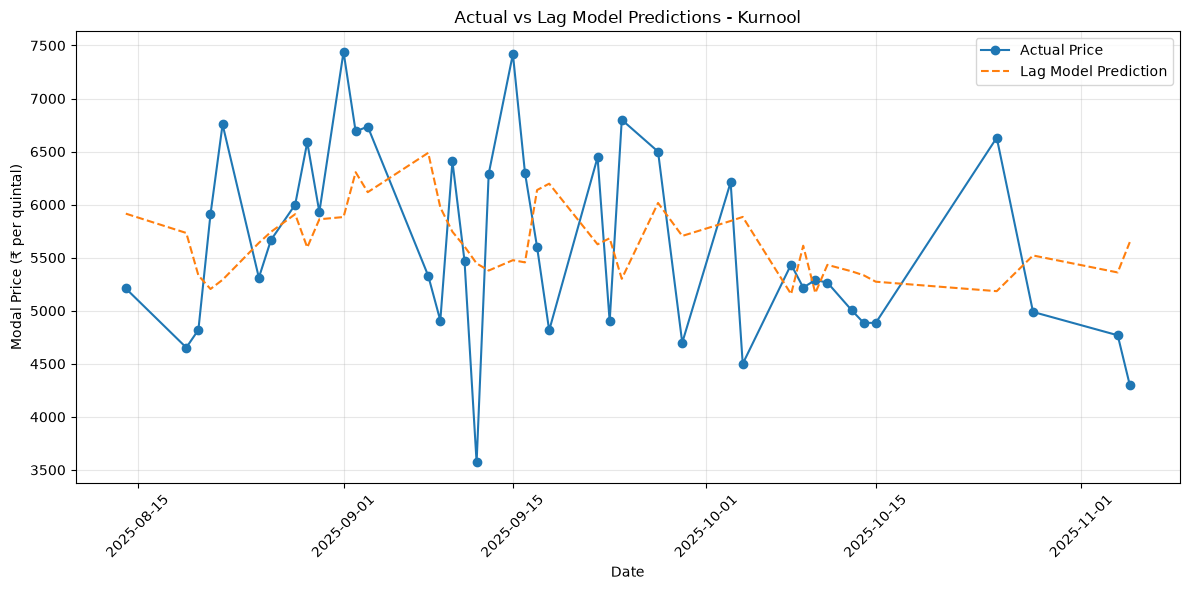

In [32]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_lag["Arrival_Date"],
    test_lag["Modal_Price"],
    label="Actual Price",
    marker="o"
)

plt.plot(
    test_lag["Arrival_Date"],
    test_lag["Lag_Prediction"],
    label="Lag Model Prediction",
    linestyle="--"
)

plt.title("Actual vs Lag Model Predictions - Kurnool")
plt.xlabel("Date")
plt.ylabel("Modal Price (₹ per quintal)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
results = pd.DataFrame({
    "Model": [
        "Constant Baseline",
        "Linear Regression",
        "Random Forest",
        "Previous Price",
        "Lag Linear Regression"
    ],
    "MAE": [
        750.63,
        809.12,
        854.47,
        912.73,
        768.85
    ],
    "RMSE": [
        884.48,
        929.58,
        997.20,
        1131.38,
        920.43
    ]
})

print(results.sort_values("MAE"))

                   Model     MAE     RMSE
0      Constant Baseline  750.63   884.48
4  Lag Linear Regression  768.85   920.43
1      Linear Regression  809.12   929.58
2          Random Forest  854.47   997.20
3         Previous Price  912.73  1131.38


In [34]:
import os

project_dir = "C:/Users/dhivakar/Desktop/Groundnut-Mandi-Price-Analysis-Forecasting"

# Save model comparison results
output_dir = os.path.join(project_dir, "visualizations")
os.makedirs(output_dir, exist_ok=True)

results.to_csv(
    os.path.join(output_dir, "model_comparison.csv"),
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [35]:
print("results" in globals())

True


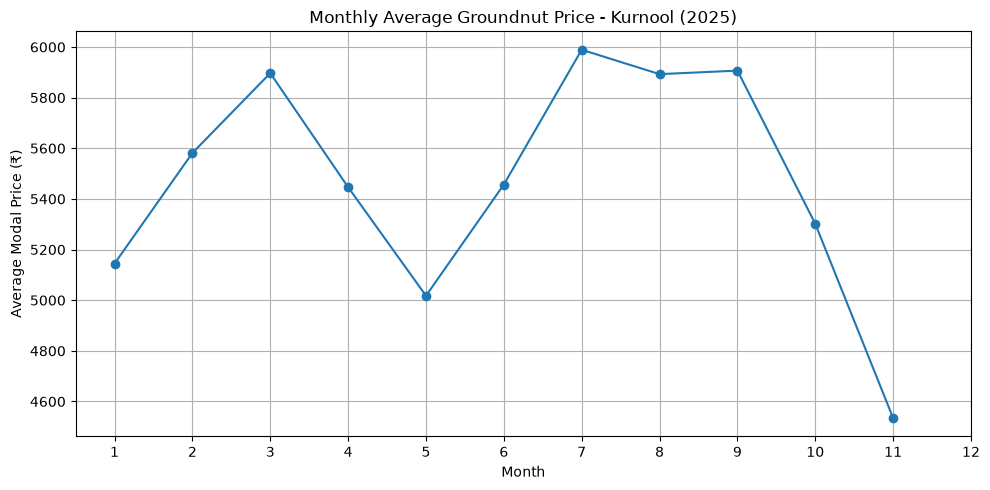

Monthly average price chart saved!


In [36]:
import os
import matplotlib.pyplot as plt

output_dir = "C:/Users/dhivakar/Desktop/Groundnut-Mandi-Price-Analysis-Forecasting/visualizations"

plt.figure(figsize=(10, 5))
plt.plot(monthly_prices["Month"], monthly_prices["Modal_Price"], marker="o")

plt.title("Monthly Average Groundnut Price - Kurnool (2025)")
plt.xlabel("Month")
plt.ylabel("Average Modal Price (₹)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()

plt.savefig(os.path.join(output_dir, "monthly_average_price.png"), dpi=300)
plt.show()

print("Monthly average price chart saved!")

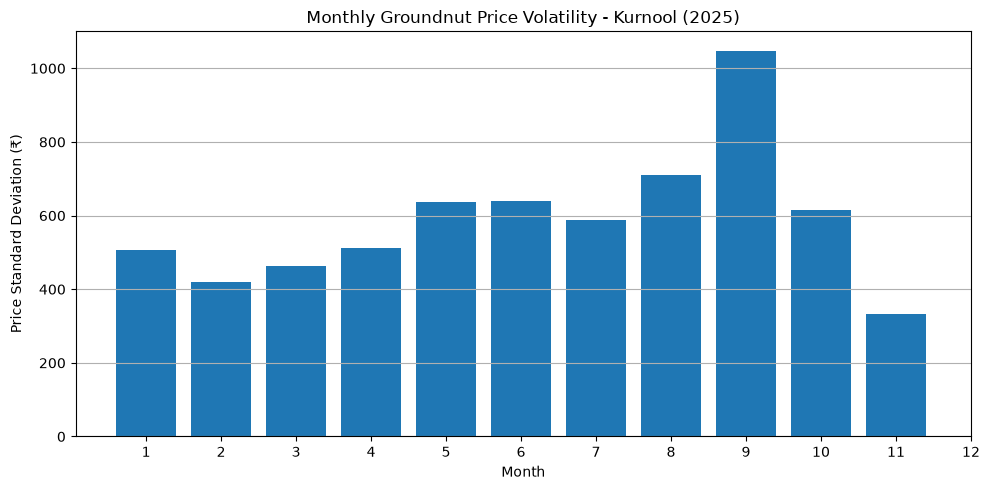

Monthly volatility chart saved!


In [37]:
output_dir = "C:/Users/dhivakar/Desktop/Groundnut-Mandi-Price-Analysis-Forecasting/visualizations"

plt.figure(figsize=(10, 5))
plt.bar(monthly_volatility["Month"], monthly_volatility["Price_Std_Dev"])

plt.title("Monthly Groundnut Price Volatility - Kurnool (2025)")
plt.xlabel("Month")
plt.ylabel("Price Standard Deviation (₹)")
plt.xticks(range(1, 13))
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(os.path.join(output_dir, "monthly_price_volatility.png"), dpi=300)
plt.show()

print("Monthly volatility chart saved!")

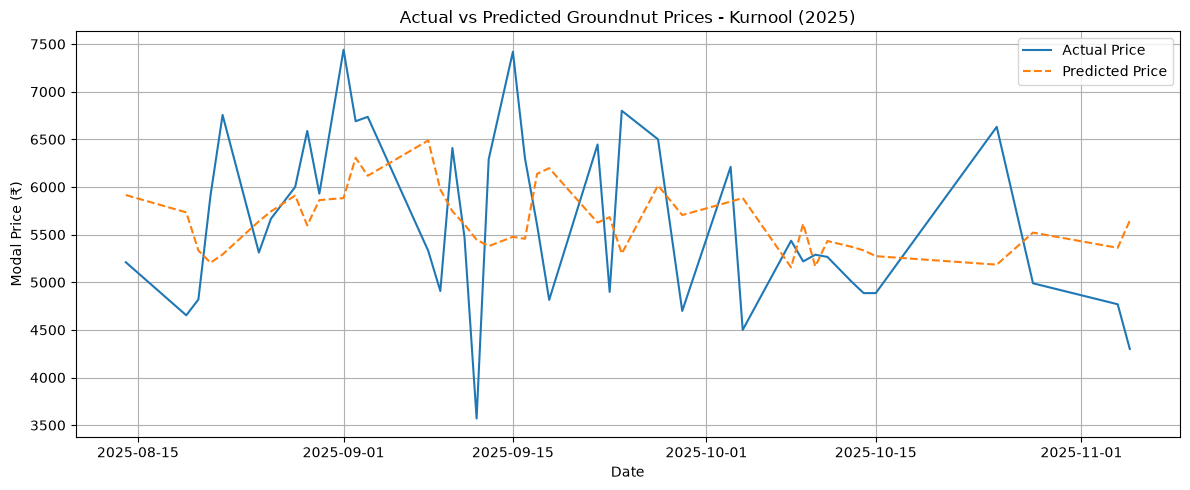

Actual vs predicted chart saved!


In [38]:
output_dir = "C:/Users/dhivakar/Desktop/Groundnut-Mandi-Price-Analysis-Forecasting/visualizations"

plt.figure(figsize=(12, 5))

plt.plot(
    test_lag["Arrival_Date"],
    test_lag["Modal_Price"],
    label="Actual Price"
)

plt.plot(
    test_lag["Arrival_Date"],
    test_lag["Lag_Prediction"],
    label="Predicted Price",
    linestyle="--"
)

plt.title("Actual vs Predicted Groundnut Prices - Kurnool (2025)")
plt.xlabel("Date")
plt.ylabel("Modal Price (₹)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "actual_vs_predicted.png"),
    dpi=300
)

plt.show()

print("Actual vs predicted chart saved!")